In [2]:
import os
import sys
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
def load_fitness(filename):
    ids = []
    fits = []
    parents = []
    with open(filename) as file :
        lines = file.read().splitlines()
        for line in lines:
            line = line.split(",")
            if(float(line[3]) > 3000):
                continue
            ids.append(int(line[0]))
            parents.append([int(line[1]),int(line[2])])
            fits.append(float(line[3]))
    return ids, parents, fits    

In [3]:
def load_parent_pool(filename):
    parent_ids = []
    with open(filename) as file:
        lines = file.readlines()
        for line in lines:
            line = line.split(',')
            ids = []
            for l in line:
                if(l == ''):
                    continue
                ids.append(int(l))
            parent_ids.append(ids)
    return parent_ids

In [4]:
def load_experiments_fitness(name, folders):
    experiments_loaded = 0
    exp_fits = []
    for folder in folders:
        #print(folder)
        ids, parents, fitnesses = load_fitness(folder + "/fitnesses.csv")
        fits_dict = {id: fit for id, fit in zip(ids,fitnesses)}
        parent_ids = load_parent_pool(folder + "/parent_pool.csv")
        fits = []

        for iteration,ids in enumerate(parent_ids):
            for id in ids:
                if not (id in fits_dict):
                    continue
                fits.append([iteration,id,fits_dict[id],len(ids),folder])

        exp_fits += fits
        experiments_loaded += 1
        print(folder, " -- Robots: ", len(ids))
    fit_data = pd.DataFrame(data=exp_fits,columns=["iteration","robot id",
                                                         "fitness",
                                                         "archive size",
                                                         "replicate"])
    fit_data["selector"] = name
    print("Total experiments loaded: ", experiments_loaded, "-- Total robots: ", len(fit_data))
    return fit_data

# Preexp MEHK-QD 1

## Convergence Analysis

In [1]:
repo_folder = "/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/"
experiments = {
    "directory" :  ['random_selector', 'sparsity_selector', 'pareto_selector'],
    "name" :       ['Random', 'Sparsity', 'Pareto'],
}

In [74]:
fit_data = []
for i, exps in enumerate(experiments["directory"]):
    print(exps)
    folders  = []
    data = []
    for folder in os.listdir(repo_folder + exps):
        folders.append(repo_folder + exps + '/' + folder)

    data = load_experiments_fitness(experiments["name"][i], folders)
    fit_data.append(data)


random_selector
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/random_selector/mehk_qd_3_10_15-24-23-3795-434208063  -- Robots:  2390
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/random_selector/mehk_qd_3_10_15-24-23-3932-2367576516  -- Robots:  2421
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/random_selector/mehk_qd_3_10_15-24-23-3959-2329057586  -- Robots:  2537
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/random_selector/mehk_qd_3_10_15-24-23-3965-3800564962  -- Robots:  2434
Total experiments loaded:  4 -- Total robots:  4475806
sparsity_selector
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/sparsity_selector/mehk_qd_3_10_15-39-25-5698-1303018214  -- Robots:  76
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/sparsity_selector/mehk_qd_6_10_13-28-37-7348-1672603518  -- Robots:  284
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_1/sparsity_selector/mehk_qd_6_10_13-28-51-1033-3002392519  -- Robots:  278
/media/leni/DATADRIVE1/evorobo_logs/preexp

In [75]:
fit_data = pd.concat(fit_data).reset_index(drop=True)

In [76]:
print(fit_data)

         iteration  robot id    fitness  archive size  \
0                0        22  1319.7500            20   
1                0        35    42.5028            20   
2                0        29    44.6361            20   
3                0         5    37.2456            20   
4                0        56    12.0936            20   
...            ...       ...        ...           ...   
4838311        183      2849   138.3060           156   
4838312        183      2920   325.7530           156   
4838313        183      2945   217.2750           156   
4838314        183      2946    44.1186           156   
4838315        183      2985   146.0040           156   

                                                 replicate selector  
0        /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
1        /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
2        /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
3        /media/leni/DATADRIVE1/evo

(0.0, 300.0)

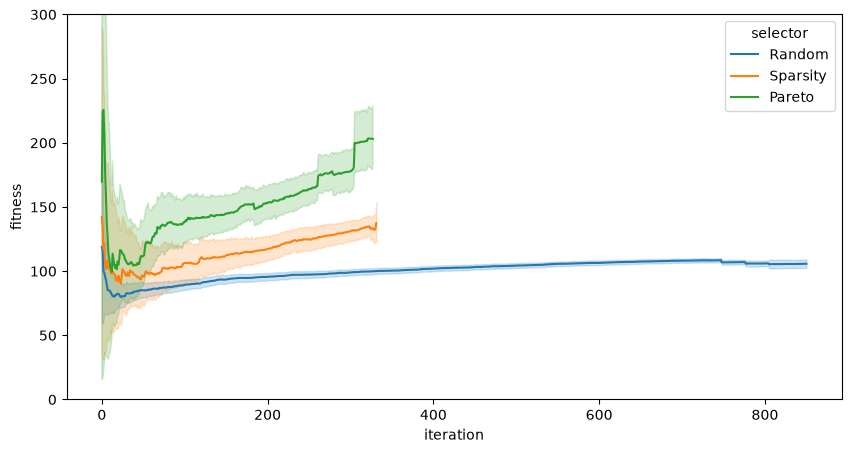

In [71]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.lineplot(fit_data,x="iteration",y="fitness",hue="selector")
ax.set_ylim(0,300)

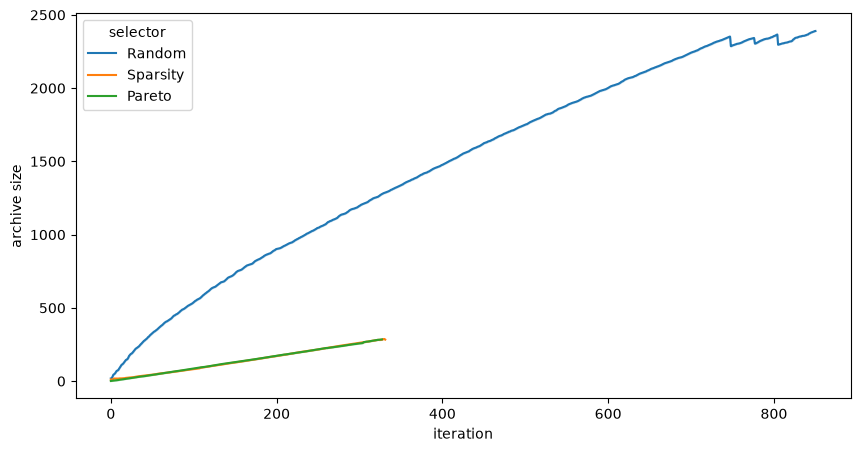

In [78]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.lineplot(fit_data,x="iteration",y="archive size",hue="selector")


# Preexp MEHK-QD 2

## Convergence Analysis

In [2]:
repo_folder = "/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/"
experiments = {
    "directory" :  ['random', 'sparsity', 'pareto'],
    "name" :       ['Random', 'Sparsity', 'Pareto'],
}

In [3]:
fit_data = []
for i, exps in enumerate(experiments["directory"]):
    print(exps)
    folders  = []
    data = []
    for folder in os.listdir(repo_folder + exps):
        folders.append(repo_folder + exps + '/' + folder)

    data = load_experiments_fitness(experiments["name"][i], folders)
    fit_data.append(data)


random


NameError: name 'load_experiments_fitness' is not defined

In [81]:
fit_data = pd.concat(fit_data).reset_index(drop=True)

In [82]:
print(fit_data)

        iteration  robot id    fitness  archive size  \
0               0         0   20.27970             1   
1               1         0   20.27970             2   
2               1        14  107.94700             2   
3               2         0   20.27970             3   
4               2        14  107.94700             3   
...           ...       ...        ...           ...   
476697        483      4124    3.31875           425   
476698        483      4021  248.78800           425   
476699        483      4024   70.85880           425   
476700        483      4029  109.87500           425   
476701        483      4116   98.56150           425   

                                                replicate selector  
0       /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
1       /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
2       /media/leni/DATADRIVE1/evorobo_logs/preexp_meh...   Random  
3       /media/leni/DATADRIVE1/evorobo_logs/preexp_

(0.0, 600.0)

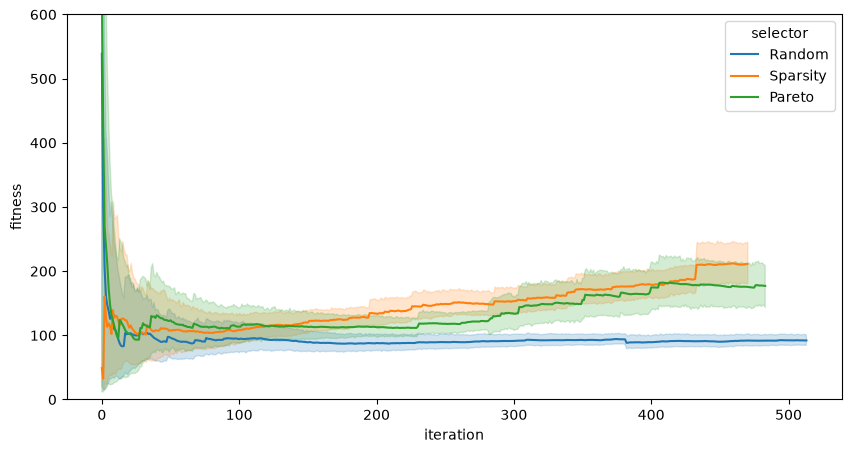

In [87]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.lineplot(fit_data,x="iteration",y="fitness",hue="selector")
ax.set_ylim(0,600)

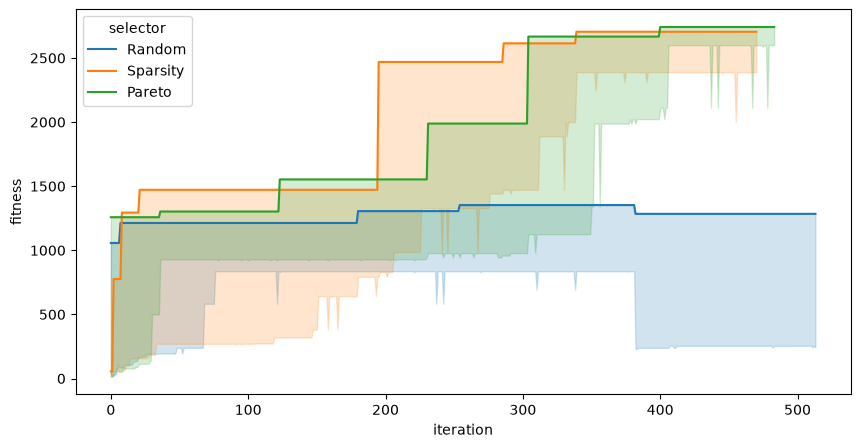

In [85]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.lineplot(fit_data,x="iteration",y="fitness",hue="selector",estimator=max)

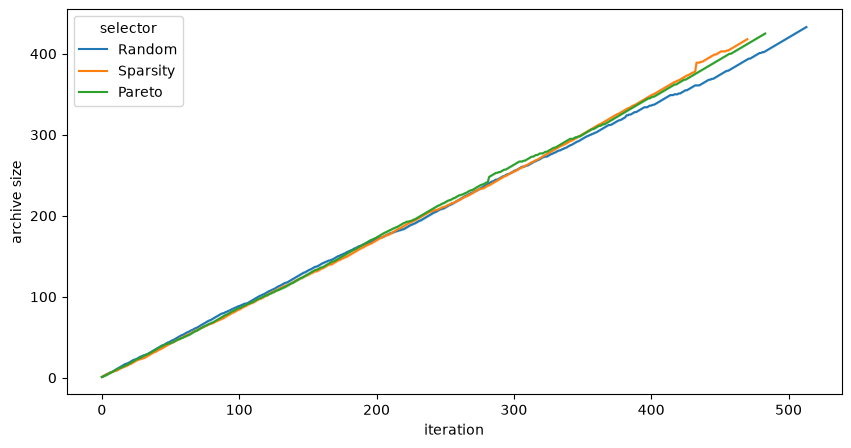

In [84]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.lineplot(fit_data,x="iteration",y="archive size",hue="selector")

## Diversity Analysis

In [35]:
import pyrobotdesign as rd
import py_async_ea as aea
import importlib
importlib.reload(aea)
importlib.reload(rd)

grammar_file = "/home/leni/git/EvoRoboGrammar/data/designs/grammar_mar19_26.dot"

In [4]:
def comparator(a, b):
    return a.get_objectives()[0] < b.get_objectives()[0]

def distance(a, b):
    return rd.tree_edit_distance(a.get_morph_genome().get_graph(), b.get_morph_genome().get_graph())

In [5]:
archives = []
archive_data = []
for exps in experiments["directory"]:
    for folder in os.listdir(repo_folder + exps):
        archive = aea.UnstructuredArchive(1,distance,comparator,aea.selectors.pareto_tournament,5)
        print("Loading archive: ", repo_folder + exps + '/' + folder)
        aea.load_archive(archive, repo_folder + exps + '/' + folder , grammar_file)
        archive.compute_sparsity_score(5)
        for solution in archive.get_solutions():
            archive_data.append([solution.id(),solution.get_objectives()[0],solution.get_sparsity_score(),folder,exps])
        archives.append([archive,exps])

Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/random/mehk_qd_10_10_12-5-16-6343-1133061259
Extract genomes 
Extract fitnesses 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/random/mehk_qd_10_10_19-54-43-3461-695504844
Extract genomes 
Extract fitnesses 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/sparsity/mehk_qd_10_10_12-6-46-6292-905293483
Extract genomes 
Extract fitnesses 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/sparsity/mehk_qd_10_10_19-54-43-3463-3798342229
Extract genomes 
Extract fitnesses 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/pareto/mehk_qd_10_10_12-6-58-8256-1945496689
Extract genomes 
Extract fitnesses 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_2/pareto/mehk_qd_10_10_19-54-43-3461-443555812
Extract genomes 
Extract fitnesses 


In [6]:
archive_data = pd.DataFrame(data=archive_data,columns=["robot id",
                                                         "fitness",
                                                         "sparsity",
                                                         "replicate",
                                                         "selector"])      


In [8]:
print(archive_data)

      robot id     fitness  sparsity                              replicate  \
0           81    13.03380       1.0  mehk_qd_10_10_12-5-16-6343-1133061259   
1           86    12.33770       1.0  mehk_qd_10_10_12-5-16-6343-1133061259   
2          158   136.21900       1.0  mehk_qd_10_10_12-5-16-6343-1133061259   
3          175    34.03120       1.0  mehk_qd_10_10_12-5-16-6343-1133061259   
4          275   167.83000       1.0  mehk_qd_10_10_12-5-16-6343-1133061259   
...        ...         ...       ...                                    ...   
2195      4115    43.65660       2.0  mehk_qd_10_10_19-54-43-3461-443555812   
2196      4116    98.56150       3.0  mehk_qd_10_10_19-54-43-3461-443555812   
2197      4118  8600.74000       4.6  mehk_qd_10_10_19-54-43-3461-443555812   
2198      4120  1651.42000       4.2  mehk_qd_10_10_19-54-43-3461-443555812   
2199      4124     3.31875       2.2  mehk_qd_10_10_19-54-43-3461-443555812   

     selector  
0      random  
1      random  
2  

In [6]:
for archive in archives:
    print("Archive size for {}: {}".format(archive[1], len(archive[0].get_solutions())))

Archive size for random: 433
Archive size for random: 320
Archive size for sparsity: 368
Archive size for sparsity: 418
Archive size for pareto: 236
Archive size for pareto: 425


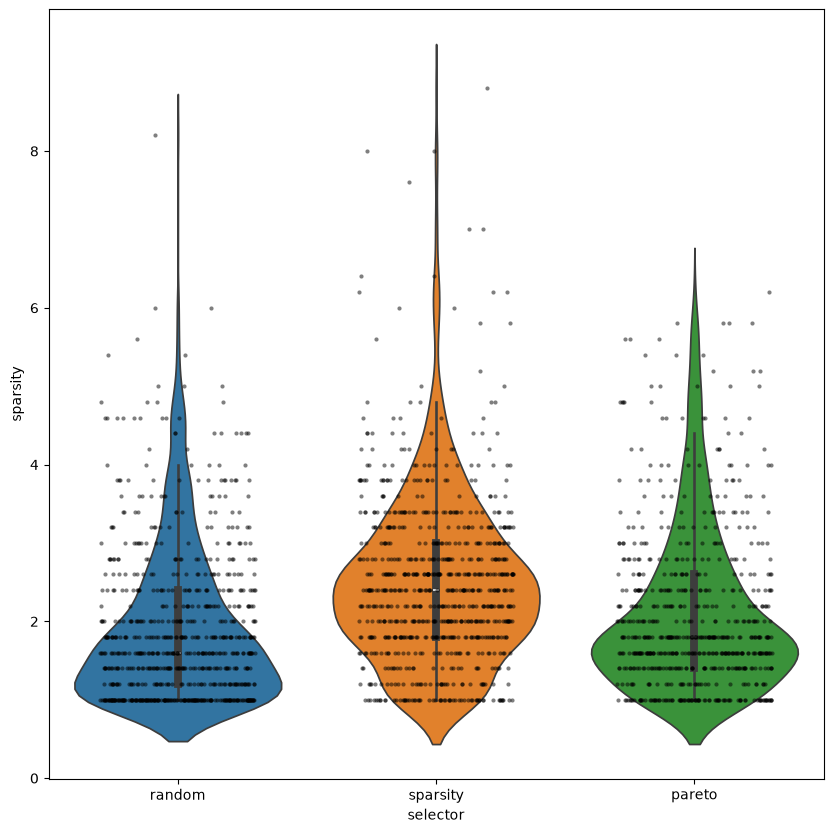

In [10]:
fig = plt.gcf()
fig.set_size_inches(10,10)
ax = sns.violinplot(archive_data,x="selector",y="sparsity",hue="selector")
ax = sns.stripplot(archive_data,x="selector",y="sparsity",color="black",size=3,alpha=0.5,jitter=0.3)

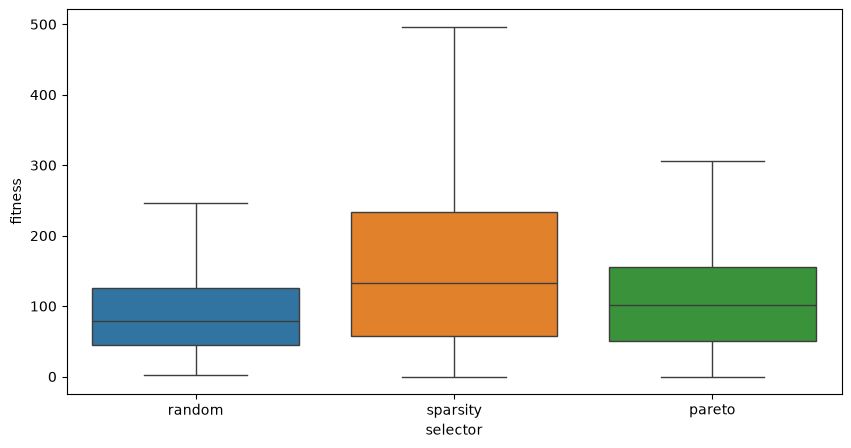

In [11]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.boxplot(archive_data,x="selector",y="fitness",hue="selector",showfliers=False)

In [8]:
selections = []
for archive in archives:
    selection = aea.selectors.pareto(archive[0].get_solutions())
    for sol in selection:
        print("Selected solution: ", sol.id(), " fitness: ", sol.get_objectives()[0], " sparsity: ", sol.get_sparsity_score(), " genome: ", "".join("{},{} ".format(gene[0], gene[1]) for gene in sol.get_morph_genome().get_rule_seq()))
    print(len(selection), " selected from ", len(archive[0].get_solutions()), " for ", archive[1])
    selections.append(selection)

Selected solution: 
 1722  fitness:  836.821  sparsity:  1.6  genome:  0,0 0,1 0,1 1,2 1,0 1,9 1,7 1,3 1,0 1,7 1,0 
Selected solution:  3466  fitness:  206.427  sparsity:  6.0  genome:  0,0 0,1 0,1 0,2 0,2 0,2 1,3 1,0 1,9 1,0 1,8 1,2 1,7 1,0 1,12 1,0 1,1 1,4 1,0 1,12 1,0 1,0 1,1 1,5 1,13 1,0 1,1 1,0 1,4 
Selected solution:  3840  fitness:  1284.28  sparsity:  1.0  genome:  0,0 0,1 1,2 1,8 1,3 1,7 1,0 1,0 
Selected solution:  4002  fitness:  277.823  sparsity:  3.4  genome:  0,0 0,2 0,1 0,1 0,3 0,1 0,3 1,2 1,12 1,1 1,9 1,0 1,3 1,0 1,5 1,8 1,9 1,13 1,5 1,6 1,0 1,0 1,0 1,0 1,13 1,4 
Selected solution:  4123  fitness:  188.038  sparsity:  6.0  genome:  0,0 0,1 0,1 0,1 0,2 0,3 0,2 0,2 1,3 1,0 1,9 1,0 1,8 1,2 1,8 1,0 1,0 1,11 1,0 1,5 1,0 1,1 1,4 1,0 1,10 1,4 1,8 1,13 1,1 1,0 1,1 1,13 1,4 
Selected solution:  4554  fitness:  229.608  sparsity:  3.6  genome:  0,0 0,1 0,1 0,1 0,2 0,2 0,1 0,1 1,3 1,0 1,9 1,0 1,8 1,2 1,9 1,0 1,0 1,11 1,0 1,5 1,0 1,1 1,7 1,13 1,4 1,0 1,1 1,8 
6  selected from  433

# Preexp MEHK-QD 3

## Convergence Analysis

In [4]:
def load_parent_pool(filename):
    parent_ids = []
    sparsity = []
    with open(filename) as file:
        lines = file.readlines()
        for line in lines:
            line = line.split(';')
            ids = []
            spar = []
            for l in line:
                if(l == ''):
                    continue
                ids.append(int(l.split(',')[0]))
                spar.append(float(l.split(',')[2]))
            parent_ids.append(ids)
            sparsity.append(spar)
    return parent_ids, sparsity

In [5]:
def load_experiments_fitness(name, folders):
    experiments_loaded = 0
    exp_fits = []
    for folder in folders:
        #print(folder)
        ids, parents, fitnesses = load_fitness(folder + "/fitnesses.csv")
        fits_dict = {id: (fit,parent[0]) for id, fit, parent in zip(ids,fitnesses,parents)}
        parent_ids, sparsity = load_parent_pool(folder + "/parent_pool.csv")
        fits = []

        for iteration, (ids, spar) in enumerate(zip(parent_ids, sparsity)):
            for id, s in zip(ids,spar):
                if not (id in fits_dict):
                    continue
                fits.append([iteration,id,s,fits_dict[id][0],fits_dict[id][1],len(ids),folder])

        exp_fits += fits
        experiments_loaded += 1
        print(folder, " -- Robots: ", len(ids))
    fit_data = pd.DataFrame(data=exp_fits,columns=["iteration","robot id",
                                                         "sparsity",
                                                         "fitness",
                                                         "parent",
                                                         "archive size",
                                                         "replicate"])
    fit_data["selector"] = name
    print("Total experiments loaded: ", experiments_loaded, "-- Total robots: ", len(fit_data))
    return fit_data

In [6]:
repo_folder = "/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/"
experiments = {
    "directory" :  ['random', 'sparsity', 'pareto'],
    "name" :       ['Random', 'Sparsity', 'Pareto'],
}

In [7]:
fit_data = []
for i, exps in enumerate(experiments["directory"]):
    print(exps)
    folders  = []
    data = []
    for folder in os.listdir(repo_folder + exps):
        folders.append(repo_folder + exps + '/' + folder)

    data = load_experiments_fitness(experiments["name"][i], folders)
    fit_data.append(data)


random
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/random/mehk_qd_12_10_11-14-39-9766-694796119  -- Robots:  1234
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/random/mehk_qd_12_10_18-19-16-6320-3175113734  -- Robots:  1033
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/random/mehk_qd_16_10_1-39-14-4279-1545379703  -- Robots:  1009
Total experiments loaded:  3 -- Total robots:  2061228
sparsity
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/sparsity/mehk_qd_12_10_11-14-41-1937-607413970  -- Robots:  489
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/sparsity/mehk_qd_13_10_2-40-11-1311-1681784350  -- Robots:  637
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/sparsity/mehk_qd_16_10_2-40-21-1400-1489097712  -- Robots:  476
Total experiments loaded:  3 -- Total robots:  750825
pareto
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/pareto/mehk_qd_12_10_11-14-43-3601-2687370978  -- Robots:  957
/media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/pareto/

In [8]:
fit_data = pd.concat(fit_data).reset_index(drop=True)

In [9]:
print(fit_data)

         iteration  robot id  sparsity    fitness  parent  archive size  \
0                0         0       0.0   26.38190      -1             1   
1                1         0       0.0   26.38190      -1             2   
2                1        42       0.0   71.89330      -1             2   
3                2         0       0.0   26.38190      -1             3   
4                2        42       0.0   71.89330      -1             3   
...            ...       ...       ...        ...     ...           ...   
5402393       2163      9653       1.4   86.29260    8966          1851   
5402394       2163      9655       1.8  280.98500    7635          1851   
5402395       2163      9657       2.2  283.42200    8414          1851   
5402396       2163      9758       2.0    4.36904    8973          1851   
5402397       2163      9658       1.4  109.98000    8298          1851   

                                                 replicate selector  
0        /media/leni/DATADRIV

(0.0, 600.0)

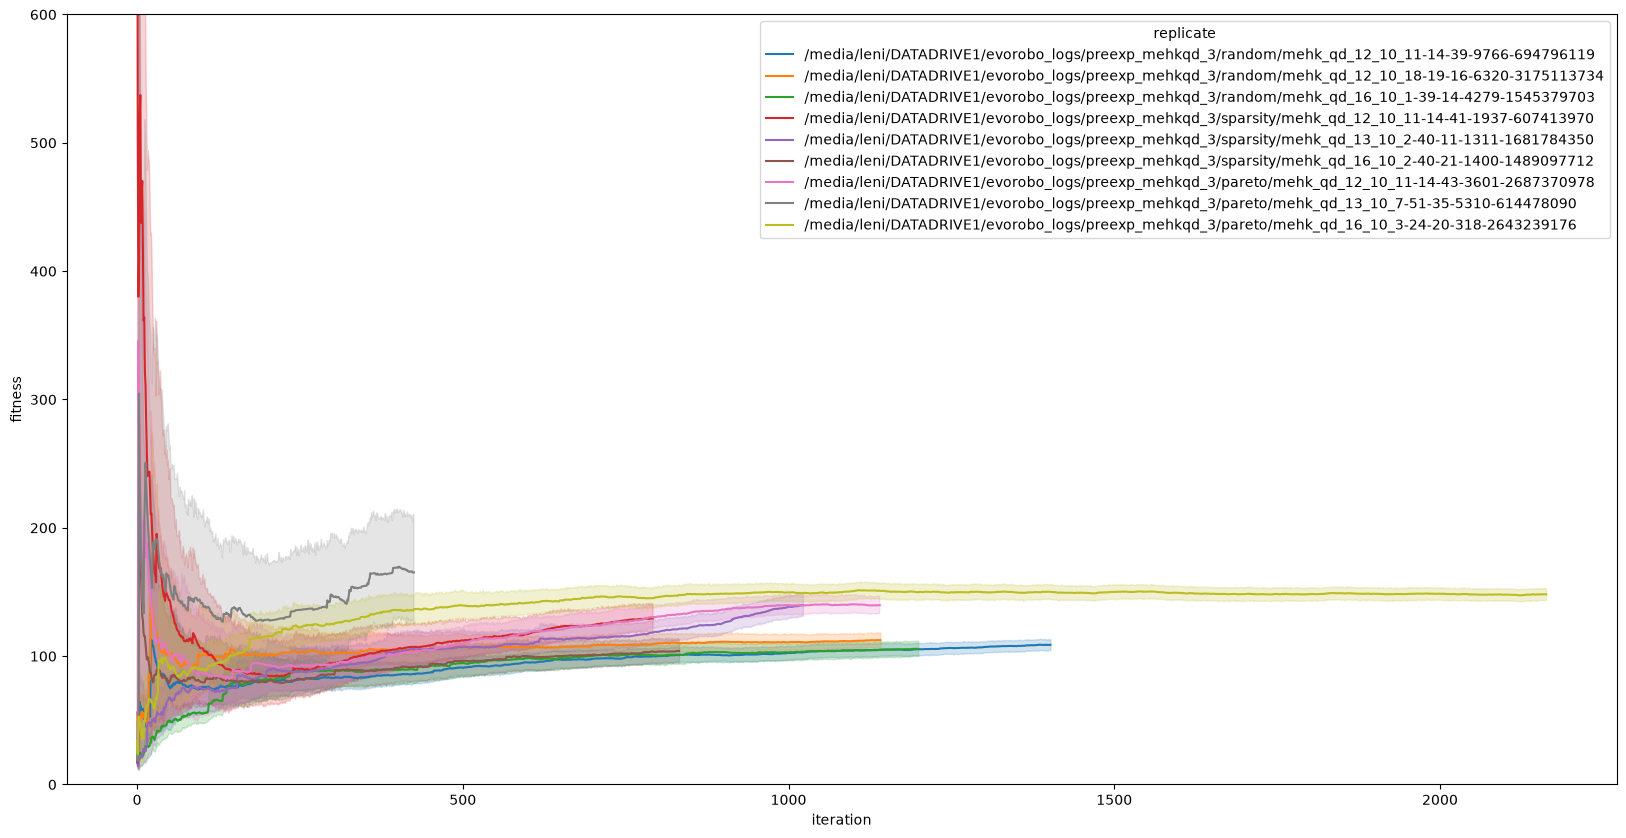

In [10]:
fig = plt.gcf()
fig.set_size_inches(20,10)
ax = sns.lineplot(fit_data,x="iteration",y="fitness",hue="replicate")
ax.set_ylim(0,600)

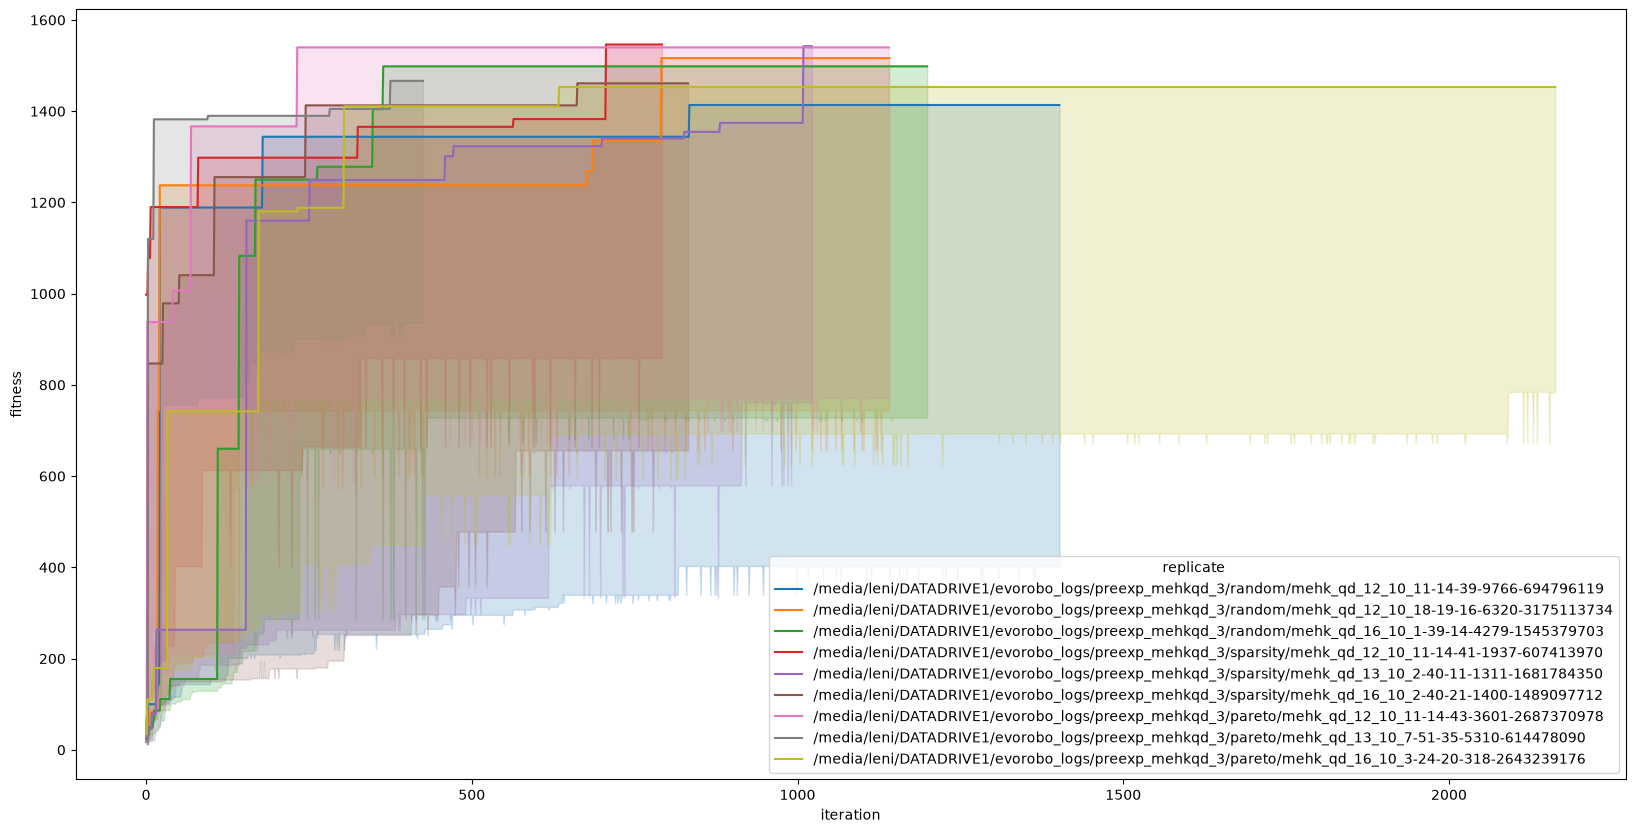

In [11]:
fig = plt.gcf()
fig.set_size_inches(20,10)
ax = sns.lineplot(fit_data,x="iteration",y="fitness",hue="replicate",estimator=max)

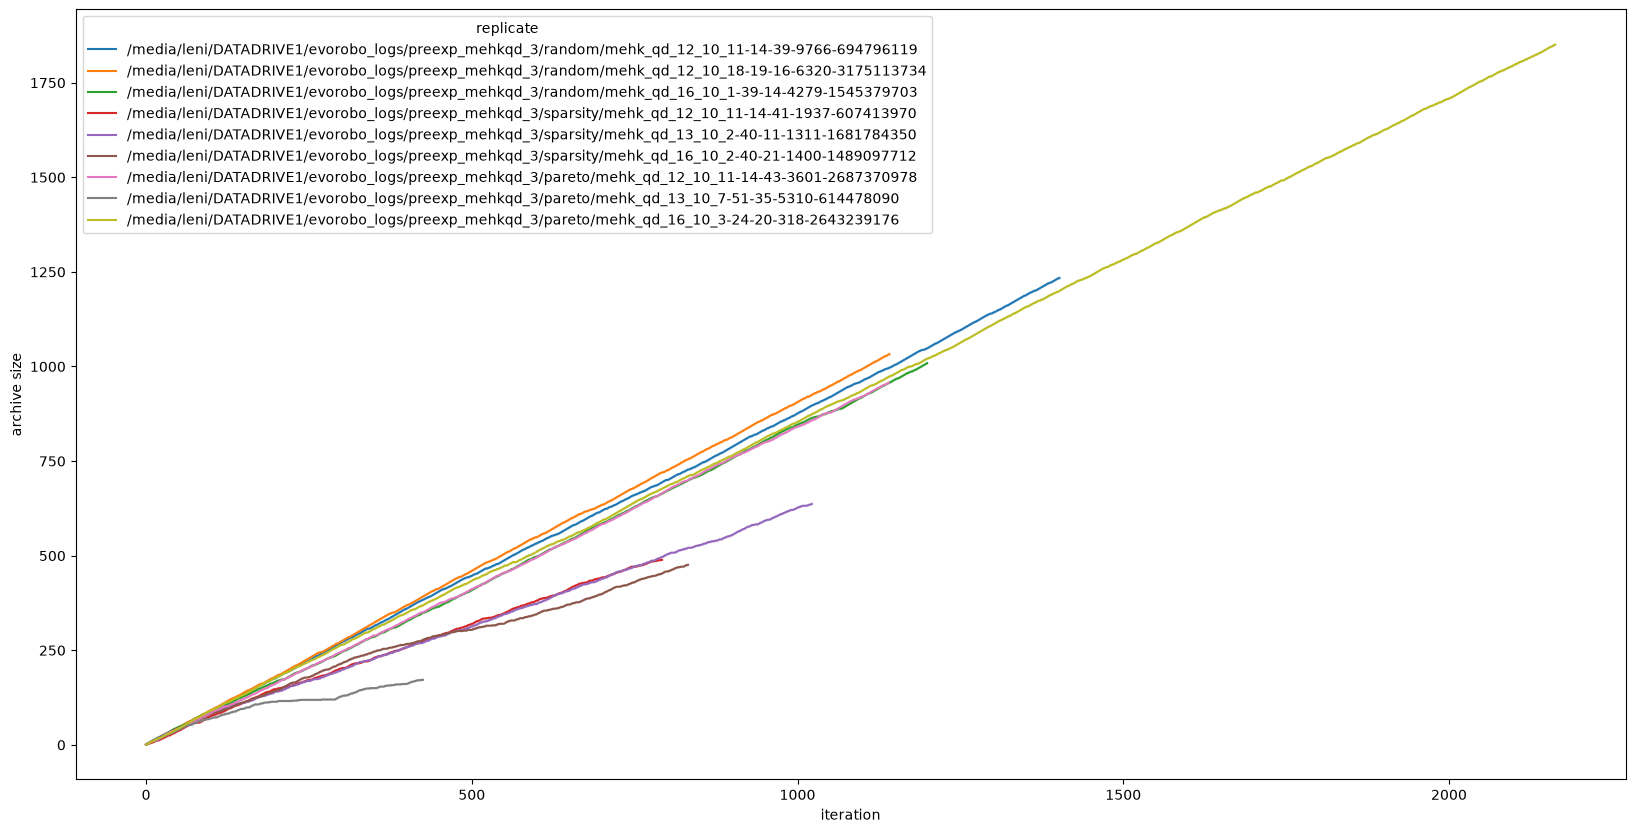

In [12]:
fig = plt.gcf()
fig.set_size_inches(20,10)
ax = sns.lineplot(fit_data,x="iteration",y="archive size",hue="replicate")

(0.0, 3.0)

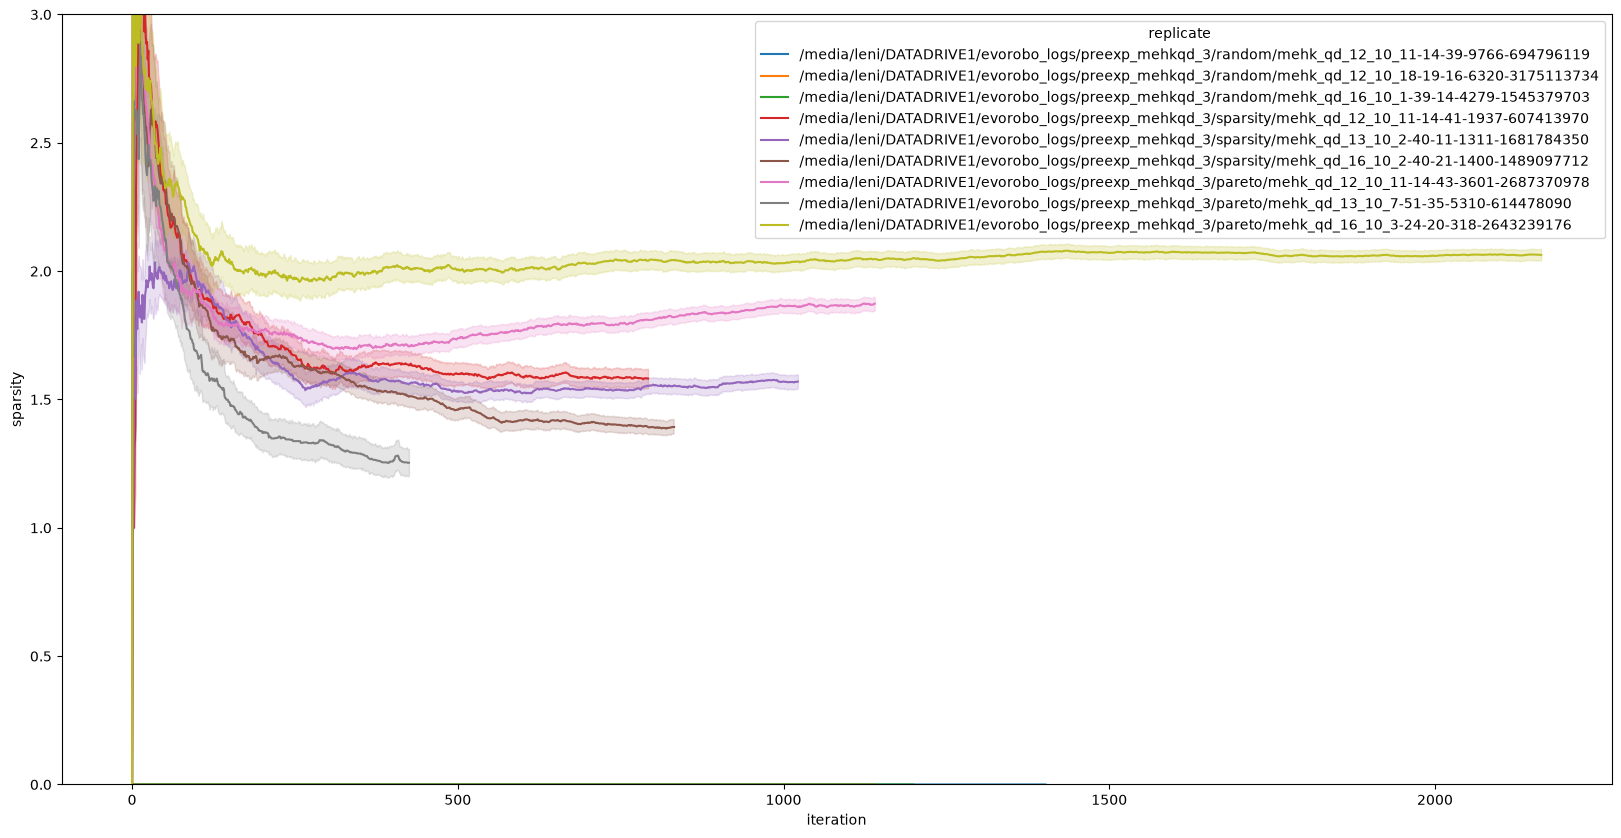

In [13]:
fig = plt.gcf()
fig.set_size_inches(20,10)
ax = sns.lineplot(fit_data,x="iteration",y="sparsity",hue="replicate")
ax.set_ylim(0,3)

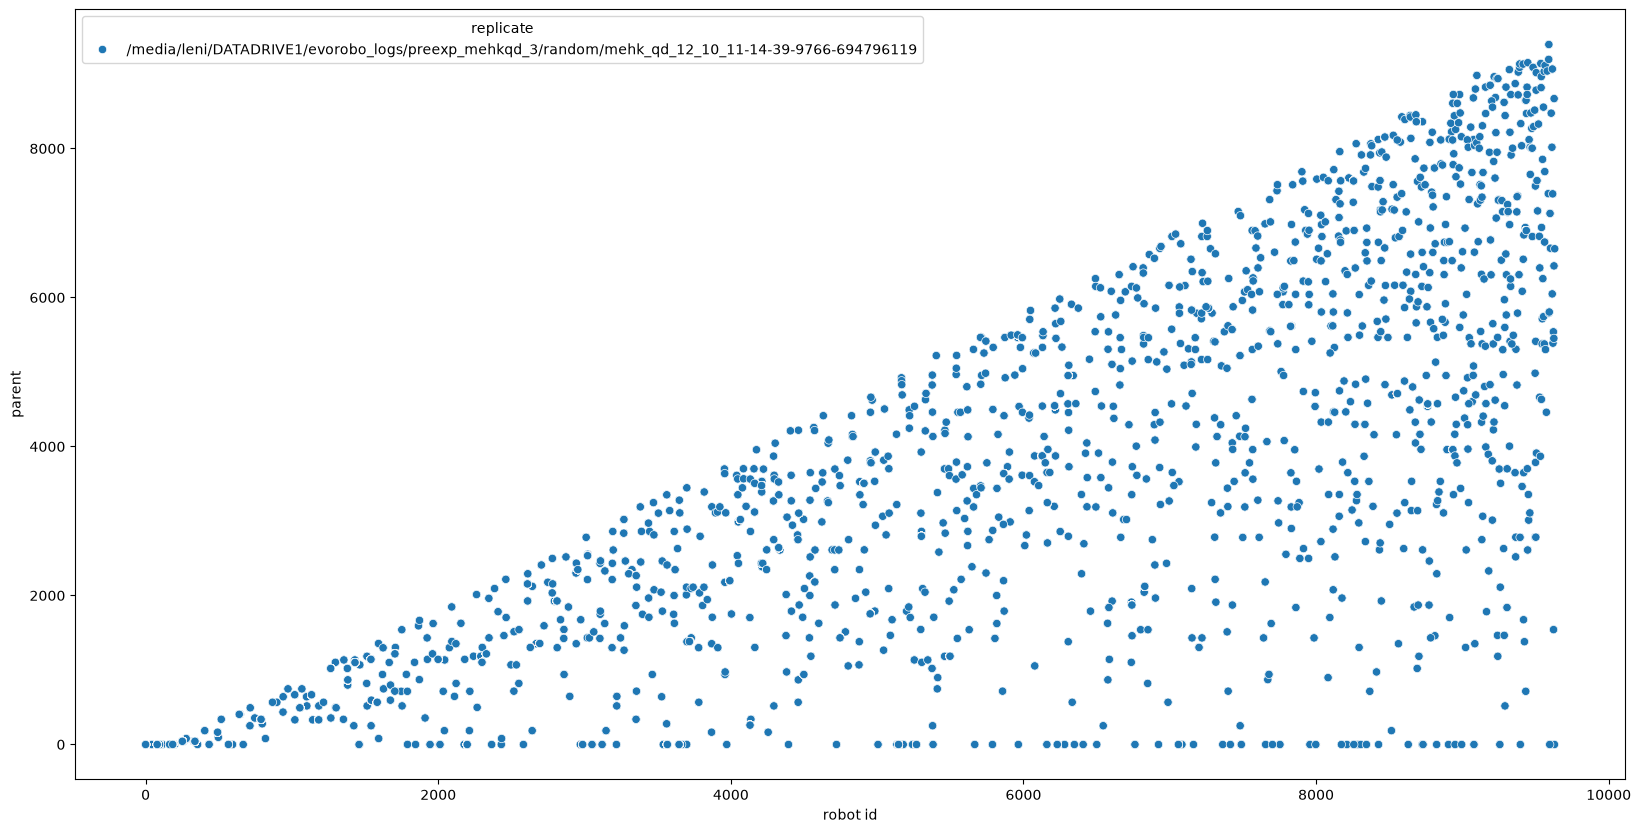

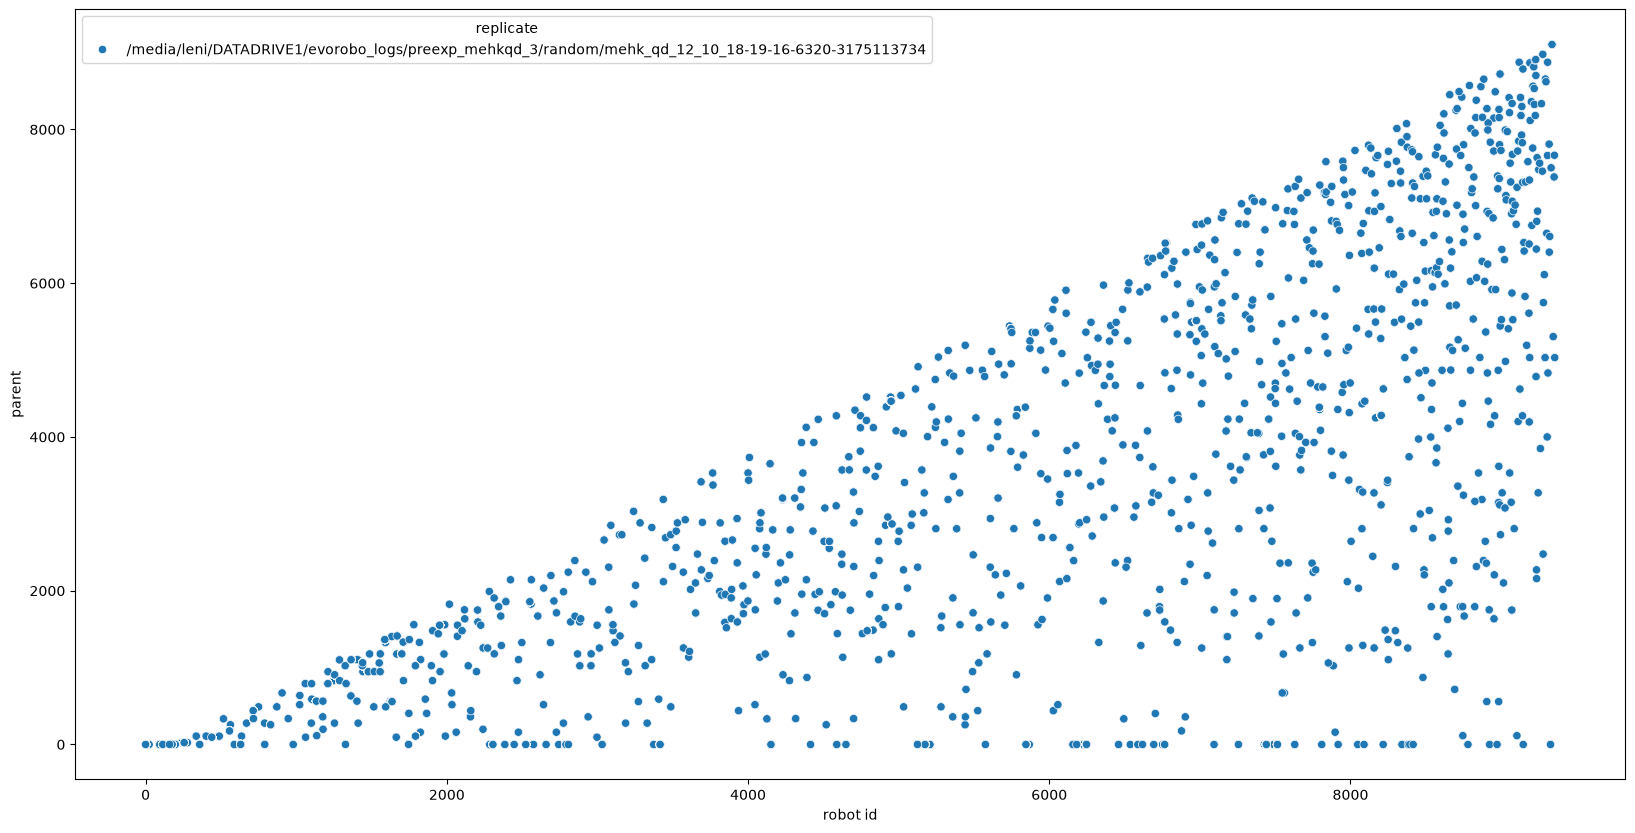

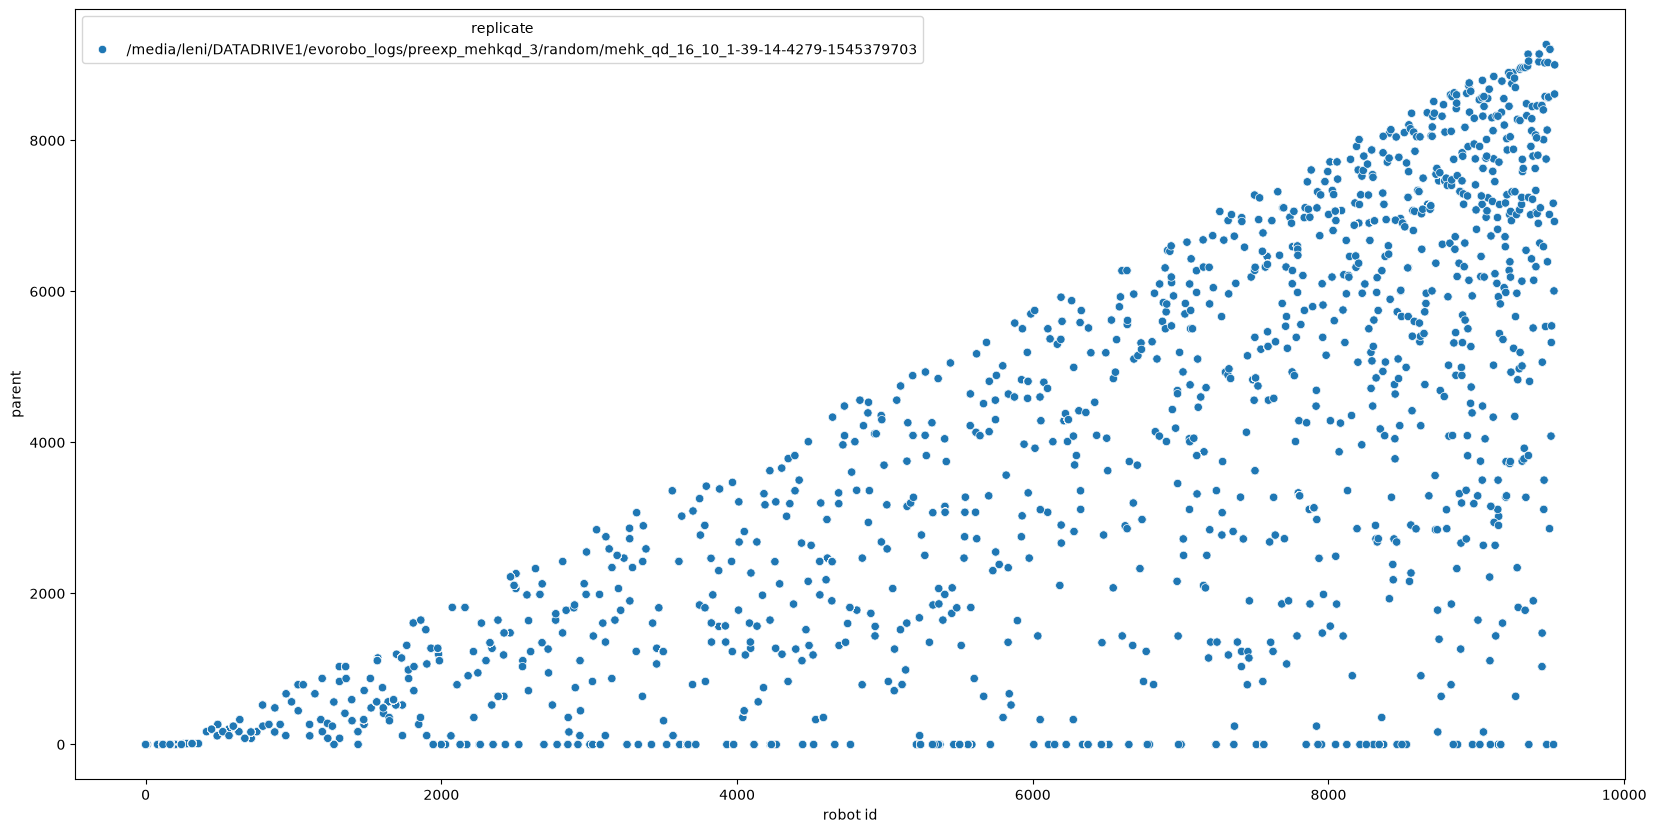

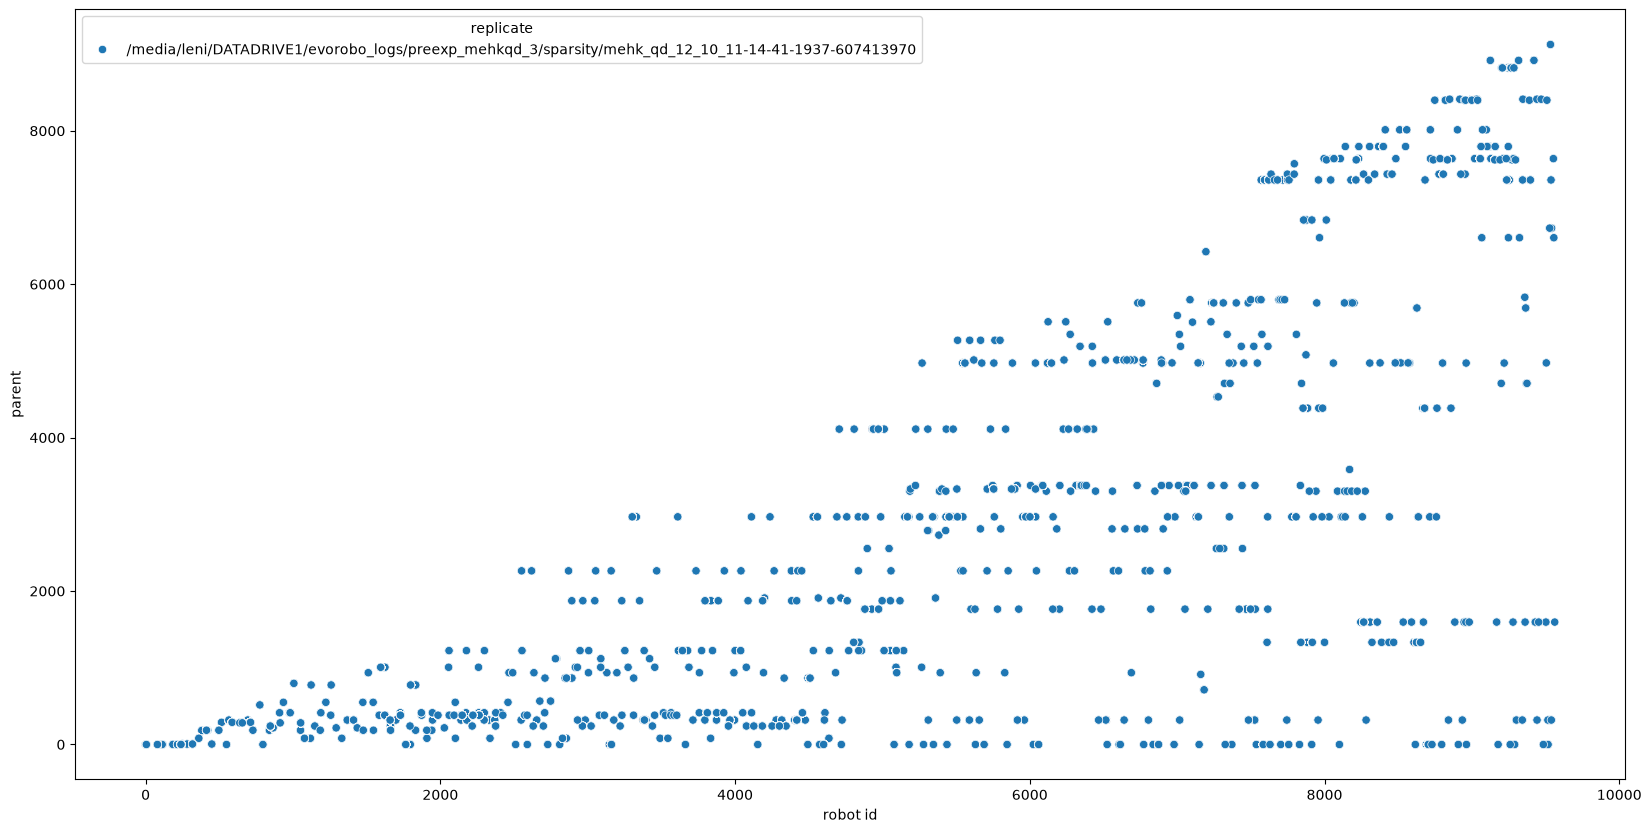

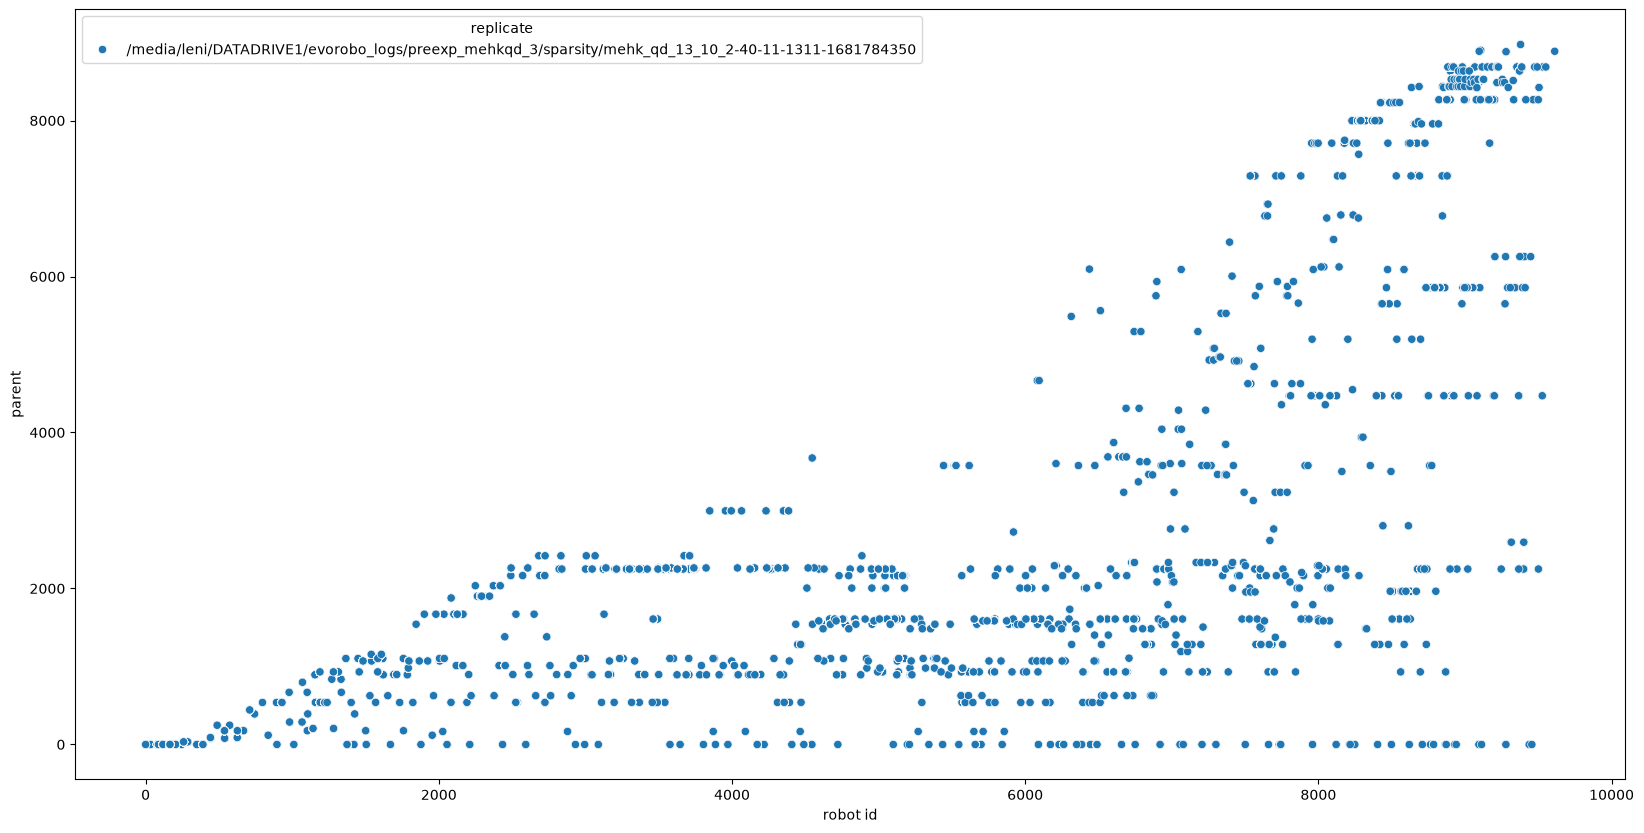

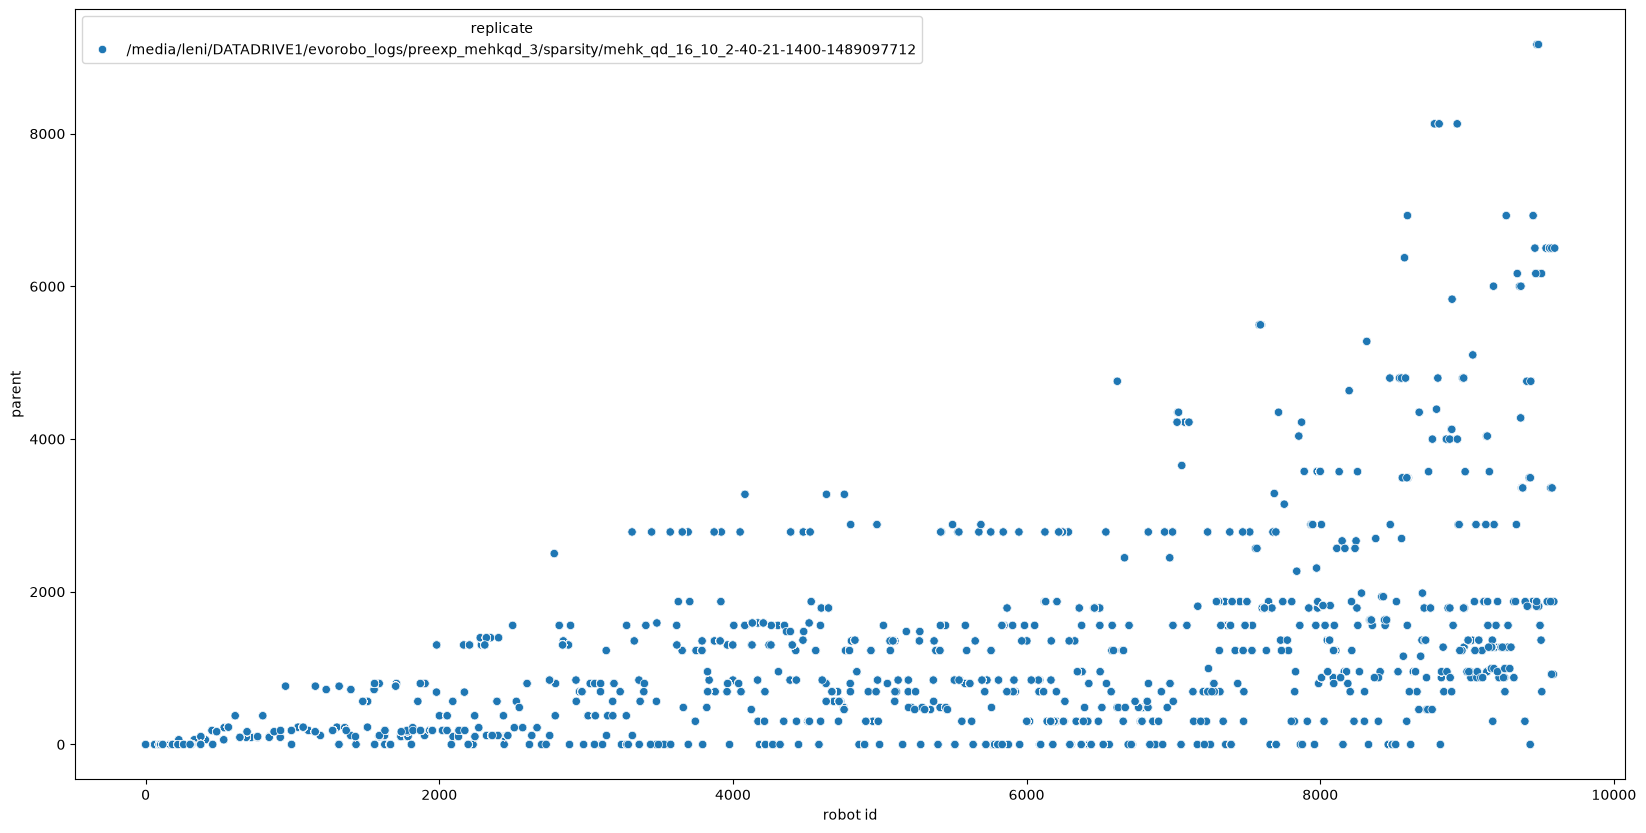

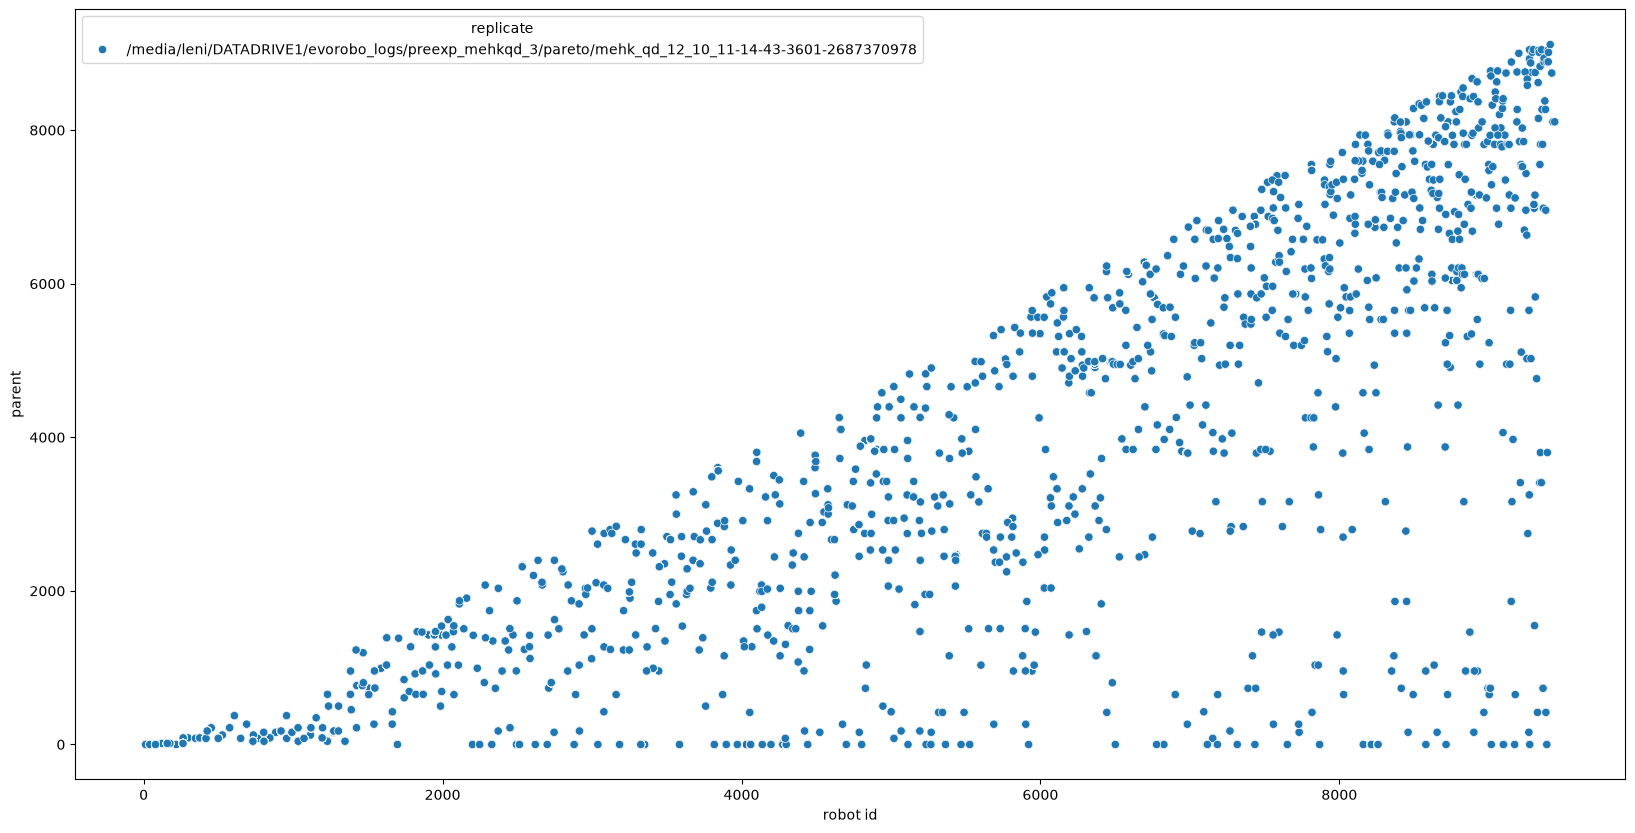

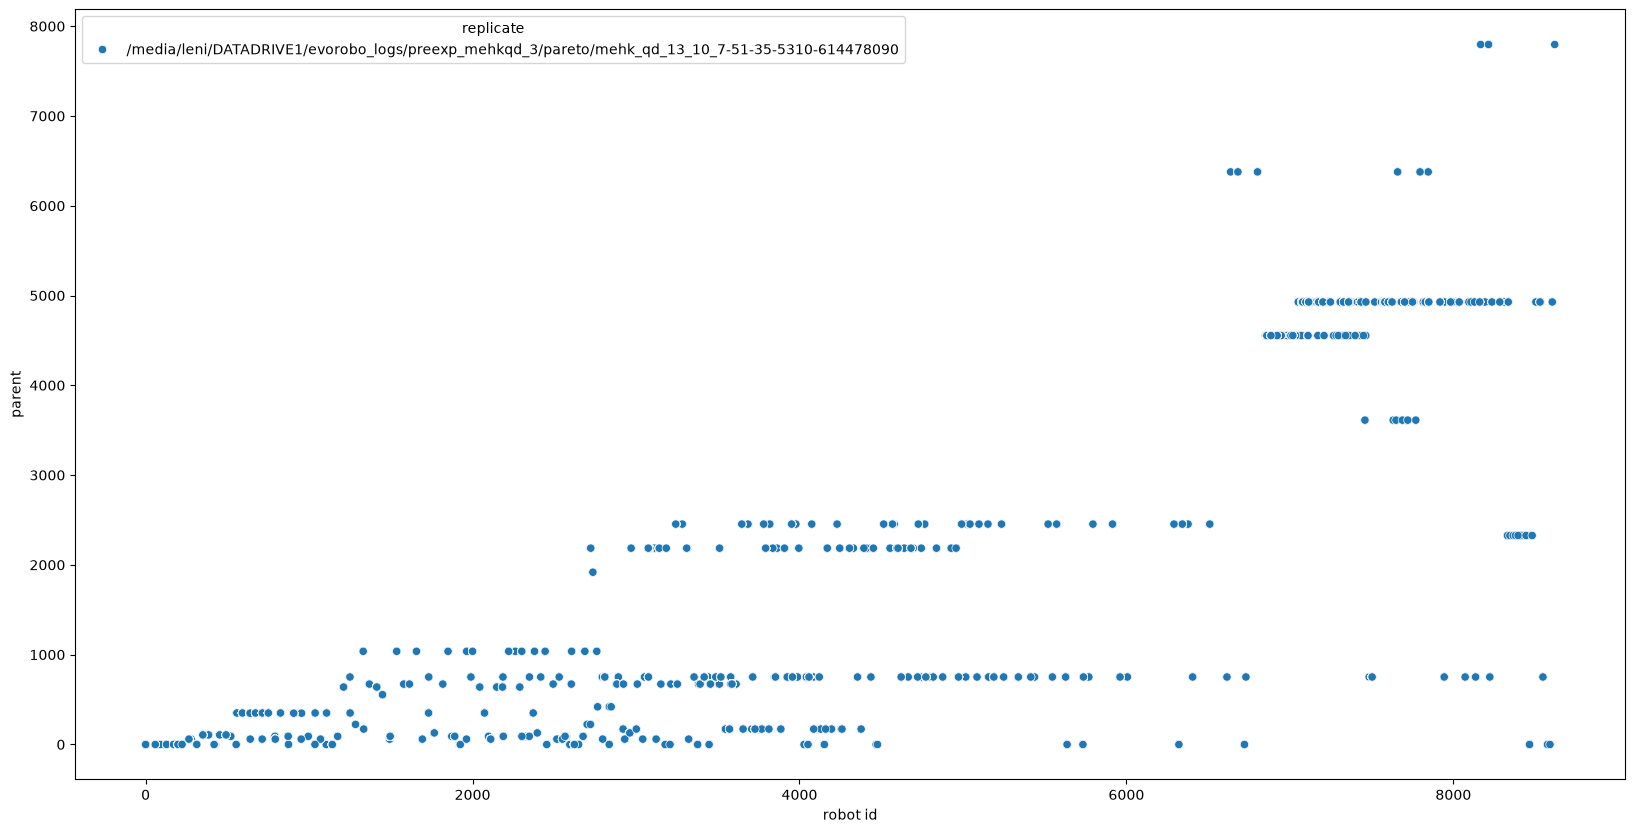

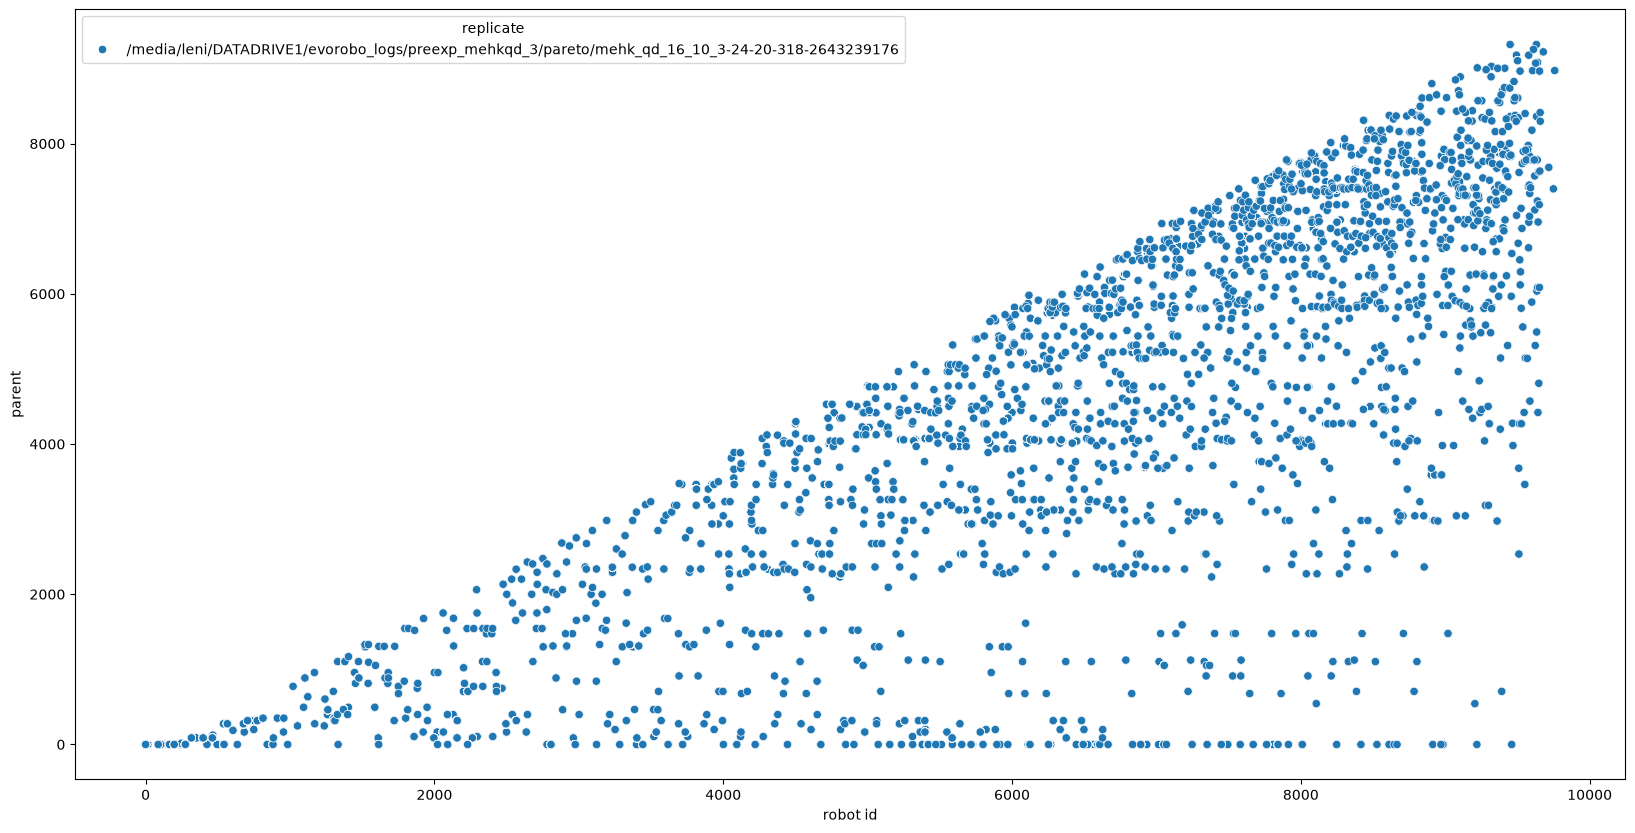

In [14]:
for exps in experiments["directory"]:
    for folder in os.listdir(repo_folder + exps):
        fig = plt.gcf()
        fig.set_size_inches(20,10)
        ax = sns.scatterplot(fit_data[fit_data["replicate"] == repo_folder + exps + '/' + folder],x="robot id",y="parent",hue="replicate")
        plt.show()


## Diversity Analysis

In [3]:
import pyrobotdesign as rd
import py_async_ea as aea
import importlib
# importlib.reload(aea)
# importlib.reload(rd)

grammar_file = "/home/leni/git/EvoRoboGrammar/data/designs/grammar_mar19_26.dot"

In [4]:
def comparator(a, b):
    return a.get_objectives()[0] < b.get_objectives()[0]

def distance(a, b):
    return rd.tree_edit_distance(a.get_morph_genome().get_graph(), b.get_morph_genome().get_graph())

In [6]:
archives = []
archive_data = []
for exps in experiments["directory"]:
    for folder in os.listdir(repo_folder + exps):
        archive = aea.UnstructuredArchive(1,distance,comparator,aea.selectors.pareto_tournament,5)
        print("Loading archive: ", repo_folder + exps + '/' + folder)
        aea.load_archive(archive, repo_folder + exps + '/' + folder , grammar_file)
        if(exps == "random"):
            archive.compute_sparsity_score(5)
        for solution in archive.get_solutions():
            archive_data.append([solution.id(),solution.get_objectives()[0],solution.get_sparsity_score(),folder,exps])
        archives.append([archive,exps])

Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/random/mehk_qd_12_10_11-14-39-9766-694796119
Extract genomes 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/random/mehk_qd_12_10_18-19-16-6320-3175113734
Extract genomes 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/sparsity/mehk_qd_12_10_11-14-41-1937-607413970
Extract genomes 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/sparsity/mehk_qd_13_10_2-40-11-1311-1681784350
Extract genomes 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/pareto/mehk_qd_12_10_11-14-43-3601-2687370978
Extract genomes 
Loading archive:  /media/leni/DATADRIVE1/evorobo_logs/preexp_mehkqd_3/pareto/mehk_qd_13_10_7-51-35-5310-614478090
Extract genomes 


In [12]:
archive_data = pd.DataFrame(data=archive_data,columns=["robot id",
                                                         "fitness",
                                                         "sparsity",
                                                         "replicate",
                                                         "selector"])      


In [7]:
print(archive_data)

      robot id   fitness  sparsity                              replicate  \
0          164   91.6113       1.0  mehk_qd_12_10_11-14-39-9766-694796119   
1          185   23.6860       1.0  mehk_qd_12_10_11-14-39-9766-694796119   
2          251   88.4465       1.0  mehk_qd_12_10_11-14-39-9766-694796119   
3          337   14.4911       1.0  mehk_qd_12_10_11-14-39-9766-694796119   
4          434   64.6006       1.0  mehk_qd_12_10_11-14-39-9766-694796119   
...        ...       ...       ...                                    ...   
4517      8548   45.1491       1.0   mehk_qd_13_10_7-51-35-5310-614478090   
4518      8576   26.3907       1.0   mehk_qd_13_10_7-51-35-5310-614478090   
4519      8591   14.3618       1.0   mehk_qd_13_10_7-51-35-5310-614478090   
4520      8605   31.5200       1.0   mehk_qd_13_10_7-51-35-5310-614478090   
4521      8620  893.3180       1.0   mehk_qd_13_10_7-51-35-5310-614478090   

     selector  
0      random  
1      random  
2      random  
3      rand

In [ ]:
for archive in archives:
    print("Archive size for {}: {}".format(archive[1], len(archive[0].get_solutions())))

Archive size for random: 1234
Archive size for random: 1033
Archive size for sparsity: 489
Archive size for sparsity: 637
Archive size for pareto: 957
Archive size for pareto: 172


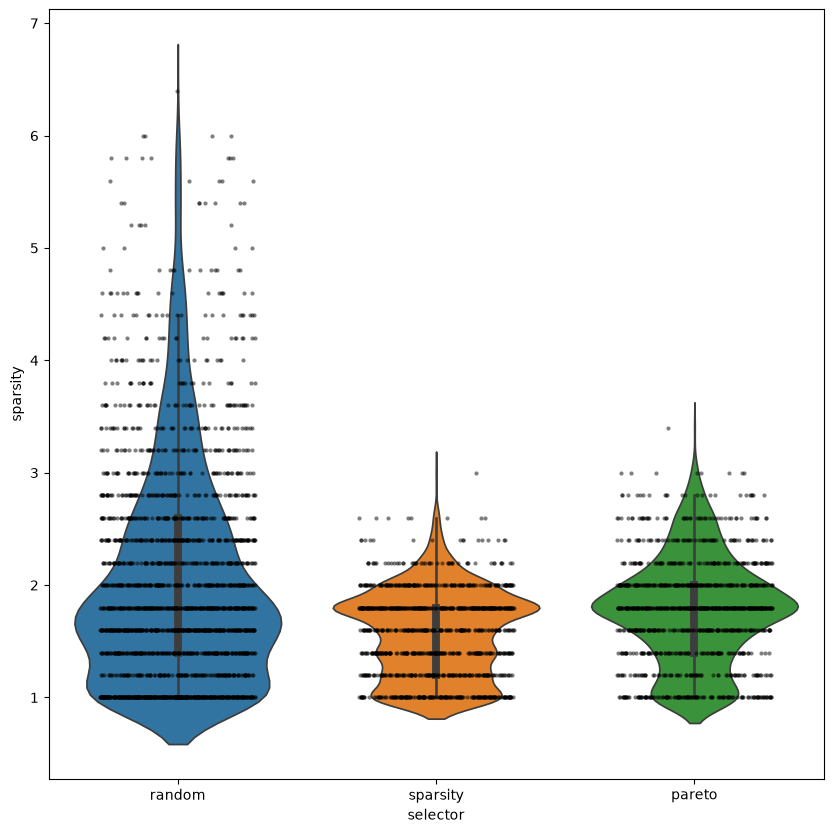

In [9]:
fig = plt.gcf()
fig.set_size_inches(10,10)
ax = sns.violinplot(archive_data,x="selector",y="sparsity",hue="selector")
ax = sns.stripplot(archive_data,x="selector",y="sparsity",color="black",size=3,alpha=0.5,jitter=0.3)

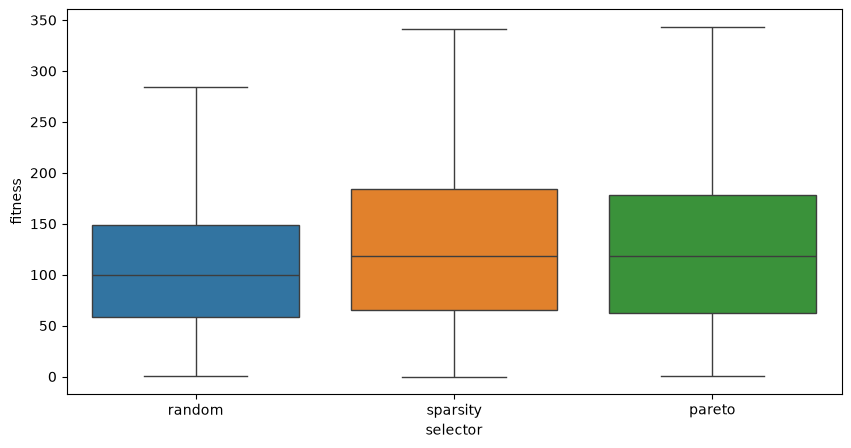

In [10]:
fig = plt.gcf()
fig.set_size_inches(10,5)
ax = sns.boxplot(archive_data,x="selector",y="fitness",hue="selector",showfliers=False)

In [ ]:
selections = []
for archive in archives:
    selection = aea.selectors.pareto(archive[0].get_solutions())
    for sol in selection:
        print("Selected solution: ", sol.id(), " fitness: ", sol.get_objectives()[0], " sparsity: ", sol.get_sparsity_score(), " genome: ", "".join("{},{} ".format(gene[0], gene[1]) for gene in sol.get_morph_genome().get_rule_seq()))
    print(len(selection), " selected from ", len(archive[0].get_solutions()), " for ", archive[1])
    selections.append(selection)

Selected solution:  6310  fitness:  313.448  sparsity:  5.2  genome:  0,0 0,2 0,3 0,3 0,3 0,3 0,3 1,4 1,8 1,12 1,7 1,3 1,1 1,0 1,2 1,5 1,12 1,11 1,4 1,4 1,13 1,12 1,4 1,13 1,5 
Selected solution:  6654  fitness:  402.986  sparsity:  2.0  genome:  0,0 0,1 0,1 0,1 0,1 0,1 0,1 1,7 1,9 1,3 1,0 1,8 1,2 1,0 1,7 1,0 1,0 1,0 1,9 1,7 1,0 1,6 1,0 
Selected solution:  6662  fitness:  229.869  sparsity:  5.4  genome:  0,0 0,2 0,1 0,3 0,3 0,1 0,1 0,3 0,3 1,6 1,9 1,12 1,5 1,2 1,3 1,0 1,0 1,1 1,8 1,10 1,0 1,0 1,4 1,5 1,10 1,7 1,11 1,4 1,4 1,13 
Selected solution:  7655  fitness:  572.579  sparsity:  1.2  genome:  0,0 0,1 0,1 1,3 1,6 1,7 1,2 1,0 1,0 1,0 
Selected solution:  7753  fitness:  1413.62  sparsity:  1.0  genome:  0,0 0,1 1,0 1,8 1,7 1,7 1,0 1,2 1,0 1,3 1,0 
Selected solution:  7958  fitness:  626.607  sparsity:  1.0  genome:  0,0 0,1 0,1 1,2 1,8 1,3 1,7 1,0 1,0 1,6 1,0 
Selected solution:  8682  fitness:  180.282  sparsity:  6.0  genome:  0,0 0,1 0,1 0,1 0,1 0,1 0,2 0,2 0,3 0,2 1,7 1,9 1,3 1

In [5]:
descriptor = aea.RoboGrammarDescriptors()
descriptor.use_all_descriptors()


In [ ]:
descriptors = []
for i in range(len(archives)):
    for j in range(len(archives[i][0].get_solutions())):
        descriptors.append(descriptor.compute_descriptor_vector(archives[i][0].get_solutions()[j].get_morph_genome().get_graph()))

pd.DataFrame(data=descriptors,columns=descriptor.get_descriptor_names())
    
        